# Evaluación Sumativa 1. Análisis exploratorio e inferencial
## Dataset: weatherAUS (datos metereológicos de Australia)

### MCDI501: Estadística Computacional para la Toma de Decisiones

Este cuaderno acompaña al informe técnico y contiene el código completo y reproducible. Sigue el mismo orden del informe: preparación y calidad de los datos, análisis exploratorio, estimación de parámetros y pruebas de hipótesis.

El análisis tiene como variable objetivo `LluviaMañana`, que indica si se registró lluvia durante el día siguiente.

## 0. Configuración y carga de datos

### 0.1 Importación de librerías y configuración del entorno

In [1]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import os

SEED = 42
np.random.seed(SEED)

# Paleta y estilo propios del informe
INK   = '#2b2b2b'
TEAL  = '#2f6b76'
OCHRE = '#c0852f'
BRICK = '#a4503e'
STEM  = '#b9b0a2'
PANEL = '#f7f3ec'
GRIDC = '#ded6c8'
cmap_corr = LinearSegmentedColormap.from_list('teal_brick', [BRICK, '#efe7d9', TEAL])
cmap_corr.set_bad('white')

plt.rcParams.update({
    'figure.dpi':120, 'savefig.dpi':200, 'font.size':10, 'font.family':'serif',
    'figure.facecolor':'white', 'axes.facecolor':PANEL,
    'axes.edgecolor':'#9a9486', 'axes.linewidth':0.8,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.titlesize':11, 'axes.titlelocation':'left', 'axes.titlepad':8,
    'text.color':INK, 'axes.labelcolor':INK, 'xtick.color':INK, 'ytick.color':INK,
})

def grid_h(ax):
    # grilla horizontal tenue por detras de los datos
    ax.set_axisbelow(True)
    ax.grid(axis='y', color=GRIDC, linewidth=0.7)
    ax.grid(axis='x', visible=False)

import pandas as pd


### 0.2 Carga del dataset

In [2]:

df = pd.read_csv("weatherAUS.csv")

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### 0.3 Traducción y preparación inicial de las variables

Con el fin de facilitar la interpretación del conjunto de datos `weatherAUS`, se traducen al español los nombres de las variables originales.

Se mantienen nombres descriptivos y coherentes con el significado de cada atributo meteorológico. Además, las variables categóricas asociadas a presencia de lluvia se traducen desde `Yes/No` a `Sí/No`.

Esta etapa no modifica los valores numéricos del conjunto de datos, sino únicamente los nombres de las columnas y las etiquetas categóricas de las variables de lluvia.

La variable objetivo del análisis será:

- **LluviaMañana**: indica si se registró lluvia al día siguiente.

Entre las principales variables explicativas se encuentran:

- temperatura mínima y máxima;
- cantidad de lluvia;
- evaporación;
- horas de sol;
- velocidad y dirección del viento;
- humedad;
- presión atmosférica;
- nubosidad;
- temperatura registrada a las 9:00 y 15:00 horas;
- presencia de lluvia durante el día actual.

In [3]:
# ============================================================
# TRADUCCIÓN DE VARIABLES DEL DATASET weatherAUS
# ============================================================

# Renombrar columnas al español
df = df.rename(columns={
    "Date": "Fecha",
    "Location": "Ubicación",
    "MinTemp": "TemperaturaMínima",
    "MaxTemp": "TemperaturaMáxima",
    "Rainfall": "Lluvia",
    "Evaporation": "Evaporación",
    "Sunshine": "HorasSol",
    "WindGustDir": "DirecciónRáfagaViento",
    "WindGustSpeed": "VelocidadRáfagaViento",
    "WindDir9am": "DirecciónViento9am",
    "WindDir3pm": "DirecciónViento3pm",
    "WindSpeed9am": "VelocidadViento9am",
    "WindSpeed3pm": "VelocidadViento3pm",
    "Humidity9am": "Humedad9am",
    "Humidity3pm": "Humedad3pm",
    "Pressure9am": "Presión9am",
    "Pressure3pm": "Presión3pm",
    "Cloud9am": "Nubosidad9am",
    "Cloud3pm": "Nubosidad3pm",
    "Temp9am": "Temperatura9am",
    "Temp3pm": "Temperatura3pm",
    "RainToday": "LluviaHoy",
    "RainTomorrow": "LluviaMañana"
})

# Traducir valores categóricos Yes / No
if "LluviaHoy" in df.columns:
    df["LluviaHoy"] = df["LluviaHoy"].replace({
        "Yes": "Sí",
        "No": "No"
    })

if "LluviaMañana" in df.columns:
    df["LluviaMañana"] = df["LluviaMañana"].replace({
        "Yes": "Sí",
        "No": "No"
    })

# Verificar resultado
print("Columnas traducidas correctamente:\n")
print(df.columns.tolist())

print("\nDimensiones del dataset:")
print(df.shape)

print("\nPrimeras filas:")
display(df.head())

Columnas traducidas correctamente:

['Fecha', 'Ubicación', 'TemperaturaMínima', 'TemperaturaMáxima', 'Lluvia', 'Evaporación', 'HorasSol', 'DirecciónRáfagaViento', 'VelocidadRáfagaViento', 'DirecciónViento9am', 'DirecciónViento3pm', 'VelocidadViento9am', 'VelocidadViento3pm', 'Humedad9am', 'Humedad3pm', 'Presión9am', 'Presión3pm', 'Nubosidad9am', 'Nubosidad3pm', 'Temperatura9am', 'Temperatura3pm', 'LluviaHoy', 'LluviaMañana']

Dimensiones del dataset:
(145460, 23)

Primeras filas:


,Fecha,Ubicación,TemperaturaMínima,TemperaturaMáxima,Lluvia,Evaporación,HorasSol,DirecciónRáfagaViento,VelocidadRáfagaViento,DirecciónViento9am,...,Humedad9am,Humedad3pm,Presión9am,Presión3pm,Nubosidad9am,Nubosidad3pm,Temperatura9am,Temperatura3pm,LluviaHoy,LluviaMañana
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


#### Verificación de las variables categóricas de lluvia

Se comprueba la correcta traducción de las categorías de las variables `LluviaHoy` y `LluviaMañana`.

Los valores esperados son:

- **Sí**: se registró lluvia.
- **No**: no se registró lluvia.
- **NaN**: dato faltante o no disponible.

Esta comprobación permite verificar que las variables categóricas se encuentran correctamente preparadas antes de realizar el análisis exploratorio y estadístico.

In [4]:
print("Valores de LluviaHoy:")
print(df["LluviaHoy"].value_counts(dropna=False))

print("\nValores de LluviaMañana:")
print(df["LluviaMañana"].value_counts(dropna=False))

Valores de LluviaHoy:
LluviaHoy
No     110319
Sí      31880
NaN      3261
Name: count, dtype: int64

Valores de LluviaMañana:
LluviaMañana
No     110316
Sí      31877
NaN      3267
Name: count, dtype: int64


## 1. Preparación y calidad de los datos

Antes de cualquier análisis revisamos la estructura, los tipos de variable, los datos faltantes, los
duplicados y los valores que podrían corresponder a registros atípicos o inconsistentes.

En este conjunto de datos meteorológico se analizarán especialmente los valores faltantes, posibles
registros duplicados, rangos de las variables meteorológicas y la asimetría de aquellas variables que
presentan colas largas o valores extremos.

In [5]:
# ============================================================
# 1. PREPARACIÓN Y CALIDAD DE LOS DATOS
# ============================================================

# Cantidad de registros y variables
n = len(df)

print(f"Número total de registros: {n:,}")
print(f"Número total de variables: {df.shape[1]}")

print("\nInformación general del dataset:\n")
df.info()

Número total de registros: 145,460
Número total de variables: 23

Información general del dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Fecha                  145460 non-null  object 
 1   Ubicación              145460 non-null  object 
 2   TemperaturaMínima      143975 non-null  float64
 3   TemperaturaMáxima      144199 non-null  float64
 4   Lluvia                 142199 non-null  float64
 5   Evaporación            82670 non-null   float64
 6   HorasSol               75625 non-null   float64
 7   DirecciónRáfagaViento  135134 non-null  object 
 8   VelocidadRáfagaViento  135197 non-null  float64
 9   DirecciónViento9am     134894 non-null  object 
 10  DirecciónViento3pm     141232 non-null  object 
 11  VelocidadViento9am     143693 non-null  float64
 12  VelocidadViento3pm     142398 non-null  fl

#### Interpretación

La inspección inicial muestra que el dataset contiene variables numéricas, como temperatura, humedad, presión, viento y precipitación, junto con variables categóricas como ubicación, dirección del viento y presencia de lluvia.

La columna `Non-Null Count` permite identificar las variables que presentan datos faltantes, mientras que `Dtype` indica el tipo de dato asociado a cada variable.

Esta revisión constituye el primer diagnóstico de calidad antes de realizar las transformaciones y análisis posteriores.

### 1.1 Datos faltantes

Se contabilizan los valores ausentes de cada variable y se calcula su porcentaje respecto del total de observaciones.

Este análisis permite identificar las variables con mayor cantidad de información incompleta y evaluar posteriormente si corresponde eliminar registros, mantener los valores faltantes o aplicar algún método de imputación.

In [6]:
# Cantidad de datos faltantes por variable
faltantes = df.isna().sum()

# Porcentaje de datos faltantes
porcentaje_faltantes = (df.isna().mean() * 100).sort_values(
    ascending=False
)

# Crear tabla resumen
tabla_faltantes = pd.DataFrame({
    "Datos faltantes": faltantes,
    "Porcentaje (%)": df.isna().mean() * 100
})

# Mostrar solo variables que tienen datos faltantes
tabla_faltantes = tabla_faltantes[
    tabla_faltantes["Datos faltantes"] > 0
].sort_values(
    by="Porcentaje (%)",
    ascending=False
)

tabla_faltantes.round(2)

,Datos faltantes,Porcentaje (%)
HorasSol,69835,48.01
Evaporación,62790,43.17
Nubosidad3pm,59358,40.81
Nubosidad9am,55888,38.42
Presión9am,15065,10.36
Presión3pm,15028,10.33
DirecciónViento9am,10566,7.26
DirecciónRáfagaViento,10326,7.10
VelocidadRáfagaViento,10263,7.06
Humedad3pm,4507,3.10


In [7]:
print(
    "Total de valores faltantes:",
    df.isna().sum().sum()
)

Total de valores faltantes: 343248


#### Interpretación de los datos faltantes

El conjunto de datos presenta valores faltantes distribuidos de manera desigual entre las variables.

Las mayores proporciones de información faltante se encuentran en `HorasSol` (**48,01 %**), `Evaporación` (**43,17 %**), `Nubosidad3pm` (**40,81 %**) y `Nubosidad9am` (**38,42 %**).

Las variables de presión presentan aproximadamente un 10 % de datos faltantes, mientras que temperatura, humedad y velocidad del viento presentan porcentajes considerablemente menores.

Debido a esta distribución de los datos faltantes, no se realizará una eliminación global de filas incompletas, ya que podría provocar una pérdida significativa de información.

### 1.2 Registros duplicados

Se verifica la existencia de filas completamente duplicadas dentro del conjunto de datos.

Los registros duplicados pueden alterar las estadísticas descriptivas y la representación de la información. Sin embargo, en un conjunto de datos meteorológicos una observación similar a otra no necesariamente corresponde a un error, por lo que se identifican antes de decidir su eliminación.

In [8]:
duplicados = df.duplicated().sum()

print(f"Número de filas duplicadas: {duplicados:,}")

Número de filas duplicadas: 0


#### Interpretación de registros duplicados

No se identificaron filas completamente duplicadas en el conjunto de datos.

Por lo tanto, no es necesario realizar una eliminación de registros por duplicidad en esta etapa.

### 1.3 Revisión de rangos y posibles valores inconsistentes

Se revisan los valores mínimos y máximos de las principales variables meteorológicas.

El objetivo es detectar posibles registros inconsistentes o valores extremos que requieran una revisión adicional. La presencia de valores extremos no implica necesariamente un error, ya que puede corresponder a eventos meteorológicos reales.

In [9]:
variables_revision = [
    "TemperaturaMínima",
    "TemperaturaMáxima",
    "Lluvia",
    "Evaporación",
    "HorasSol",
    "VelocidadRáfagaViento",
    "VelocidadViento9am",
    "VelocidadViento3pm",
    "Humedad9am",
    "Humedad3pm",
    "Presión9am",
    "Presión3pm",
    "Nubosidad9am",
    "Nubosidad3pm",
    "Temperatura9am",
    "Temperatura3pm"
]

resumen_rangos = []

for columna in variables_revision:
    if columna in df.columns:
        resumen_rangos.append({
            "Variable": columna,
            "Mínimo": df[columna].min(),
            "Máximo": df[columna].max(),
            "Media": df[columna].mean(),
            "Mediana": df[columna].median()
        })

resumen_rangos = pd.DataFrame(resumen_rangos)

resumen_rangos.round(2)

,Variable,Mínimo,Máximo,Media,Mediana
0,TemperaturaMínima,-8.5,33.9,12.19,12.0
1,TemperaturaMáxima,-4.8,48.1,23.22,22.6
2,Lluvia,0.0,371.0,2.36,0.0
3,Evaporación,0.0,145.0,5.47,4.8
4,HorasSol,0.0,14.5,7.61,8.4
5,VelocidadRáfagaViento,6.0,135.0,40.04,39.0
6,VelocidadViento9am,0.0,130.0,14.04,13.0
7,VelocidadViento3pm,0.0,87.0,18.66,19.0
8,Humedad9am,0.0,100.0,68.88,70.0
9,Humedad3pm,0.0,100.0,51.54,52.0


#### Interpretación de los rangos

La revisión de mínimos y máximos permite comprobar si los valores observados son coherentes con la naturaleza de cada variable.

Por ejemplo, la humedad debería encontrarse dentro de valores físicamente razonables y las temperaturas deben mantenerse dentro de rangos meteorológicamente posibles.

La comparación entre media y mediana también permite obtener una primera señal sobre la forma de las distribuciones.

Cuando la media y la mediana presentan diferencias importantes, puede existir asimetría o presencia de valores extremos.

Los valores extremos no serán eliminados automáticamente, ya que podrían representar fenómenos meteorológicos reales.

### 1.4 Asimetría de variables numéricas

La asimetría permite evaluar la forma de la distribución de las variables numéricas.

Valores cercanos a cero representan distribuciones aproximadamente simétricas. Valores positivos indican una cola más extensa hacia valores altos y valores negativos una cola más extensa hacia valores bajos.

Este indicador permite identificar variables que pueden contener valores extremos o distribuciones muy alejadas de la simetría.

In [10]:
# Seleccionar variables numéricas
variables_numericas = df.select_dtypes(include=np.number)

# Calcular asimetría
asimetria = variables_numericas.skew().sort_values(
    ascending=False
)

asimetria.round(2)

Lluvia                   9.84
Evaporación              3.76
VelocidadRáfagaViento    0.87
VelocidadViento9am       0.78
VelocidadViento3pm       0.63
Temperatura3pm           0.24
TemperaturaMáxima        0.22
Temperatura9am           0.09
Humedad3pm               0.03
TemperaturaMínima        0.02
Presión3pm              -0.05
Presión9am              -0.10
Nubosidad3pm            -0.23
Nubosidad9am            -0.23
Humedad9am              -0.48
HorasSol                -0.50
dtype: float64

#### Interpretación de la asimetría

El análisis muestra que algunas variables meteorológicas presentan distribuciones asimétricas.

En particular, `Lluvia` presenta una asimetría positiva elevada, lo que indica que existe una gran cantidad de días con poca o ninguna precipitación y una menor cantidad de eventos con lluvias intensas.

Las variables con asimetría cercana a cero presentan distribuciones más equilibradas respecto de su media.

Estas diferencias deben considerarse al interpretar las estadísticas descriptivas y al seleccionar las técnicas de análisis posteriores.

### 1.5 Revisión de la variable objetivo

La variable objetivo del análisis es **LluviaMañana**, que indica si se registró lluvia durante el día siguiente.

Se analiza la frecuencia y proporción de las categorías `Sí` y `No`, además de identificar posibles valores faltantes.

In [11]:
tabla_objetivo = pd.DataFrame({
    "Frecuencia": df["LluviaMañana"].value_counts(dropna=False),
    "Porcentaje (%)": (
        df["LluviaMañana"]
        .value_counts(normalize=True, dropna=False)
        * 100
    )
})

tabla_objetivo.round(2)

,Frecuencia,Porcentaje (%)
LluviaMañana,,
No,110316,75.84
Sí,31877,21.91
NaN,3267,2.25


#### Interpretación de la variable objetivo

La variable `LluviaMañana` presenta una mayor proporción de registros correspondientes a la categoría `No` respecto de la categoría `Sí`.

Esto indica que en el conjunto de datos existen más días en los que no llueve al día siguiente que días en los que sí se registra precipitación.

Esta diferencia evidencia un desbalance entre las categorías de la variable objetivo, aspecto que debe considerarse en los análisis posteriores y especialmente en un eventual desarrollo de modelos predictivos.

### 1.6 Decisiones de tratamiento

A partir de la revisión inicial de calidad de los datos, se adoptan las siguientes decisiones:

- Los valores faltantes no serán eliminados automáticamente del conjunto completo de datos.
- En los análisis que requieran variables específicas se trabajará con los casos disponibles.
- No se identificaron filas completamente duplicadas, por lo que no fue necesario aplicar un tratamiento por duplicidad.
- Los valores extremos no serán descartados automáticamente, ya que pueden representar eventos meteorológicos reales.
- La variable `LluviaMañana` se conservará inicialmente como variable categórica.
- Posteriormente, la variable objetivo podrá transformarse a formato binario para realizar estimaciones, comparaciones y pruebas estadísticas.

Estas decisiones permiten conservar la mayor cantidad de información disponible y evitar modificaciones prematuras que puedan alterar la representación del fenómeno meteorológico estudiado.

In [12]:
# Crear versión binaria de la variable objetivo
df["LluviaMañana_bin"] = df["LluviaMañana"].map({
    "No": 0,
    "Sí": 1
})

# Verificar la transformación
df[["LluviaMañana", "LluviaMañana_bin"]].head(10)

,LluviaMañana,LluviaMañana_bin
0,No,0.0
1,No,0.0
2,No,0.0
3,No,0.0
4,No,0.0
5,No,0.0
6,No,0.0
7,No,0.0
8,Sí,1.0
9,No,0.0


#### Interpretación de la transformación

La variable categórica `LluviaMañana` se transformó adicionalmente en una variable binaria denominada `LluviaMañana_bin`.

En esta representación:

- `0` indica que no se registró lluvia al día siguiente.
- `1` indica que sí se registró lluvia al día siguiente.

La variable original se conserva para facilitar la interpretación de tablas y gráficos, mientras que la versión binaria podrá utilizarse posteriormente en cálculos estadísticos, estimaciones de proporciones y pruebas de hipótesis.

Esta transformación no modifica la información original, sino que proporciona una representación numérica de la variable objetivo.

## 2. Análisis exploratorio de datos

En esta etapa se analiza el comportamiento general de las variables meteorológicas mediante estadísticas descriptivas y visualizaciones.

El objetivo es identificar patrones, distribuciones, posibles valores extremos y relaciones entre las variables antes de realizar estimaciones y pruebas de hipótesis.

Se mantiene la estructura del análisis original, pero adaptada a las características del conjunto de datos meteorológico.

### 2.1 Estadística descriptiva

Se calculan medidas descriptivas para las variables numéricas del conjunto de datos.

Para cada variable se presentan:

- Media
- Mediana
- Desviación estándar
- Valor mínimo
- Valor máximo
- Asimetría

Estas medidas permiten evaluar la tendencia central, la dispersión y la forma de las distribuciones.

In [13]:
# Seleccionar solo variables numéricas
numericas = df.select_dtypes(include=np.number)

# Tabla descriptiva
desc = numericas.describe().T[
    ['mean', '50%', 'std', 'min', 'max']
]

# Agregar asimetría
desc['skew'] = numericas.skew()

# Renombrar columnas
desc.columns = [
    'Media',
    'Mediana',
    'Desv. est.',
    'Mínimo',
    'Máximo',
    'Asimetría'
]

desc.round(2)

,Media,Mediana,Desv. est.,Mínimo,Máximo,Asimetría
TemperaturaMínima,12.19,12.0,6.40,-8.5,33.9,0.02
TemperaturaMáxima,23.22,22.6,7.12,-4.8,48.1,0.22
Lluvia,2.36,0.0,8.48,0.0,371.0,9.84
Evaporación,5.47,4.8,4.19,0.0,145.0,3.76
HorasSol,7.61,8.4,3.79,0.0,14.5,-0.50
VelocidadRáfagaViento,40.04,39.0,13.61,6.0,135.0,0.87
VelocidadViento9am,14.04,13.0,8.92,0.0,130.0,0.78
VelocidadViento3pm,18.66,19.0,8.81,0.0,87.0,0.63
Humedad9am,68.88,70.0,19.03,0.0,100.0,-0.48
Humedad3pm,51.54,52.0,20.80,0.0,100.0,0.03


In [14]:
# Variables meteorológicas numéricas, excluyendo códigos del objetivo.
columnas_numericas = [
    c for c in df.select_dtypes(include=np.number).columns
    if not c.endswith('_bin')
]

numericas = df[columnas_numericas]

desc = numericas.describe().T[
    ['count', 'mean', '50%', 'std', 'min', 'max']
]

desc.columns = [
    'n disponible', 'Media', 'Mediana',
    'Desv. est.', 'Mínimo', 'Máximo'
]

desc['Asimetría'] = numericas.skew()
desc['Exceso de curtosis'] = numericas.kurt()

display(desc.round(2))

,n disponible,Media,Mediana,Desv. est.,Mínimo,Máximo,Asimetría,Exceso de curtosis
TemperaturaMínima,143975.0,12.19,12.0,6.40,-8.5,33.9,0.02,-0.48
TemperaturaMáxima,144199.0,23.22,22.6,7.12,-4.8,48.1,0.22,-0.22
Lluvia,142199.0,2.36,0.0,8.48,0.0,371.0,9.84,178.15
Evaporación,82670.0,5.47,4.8,4.19,0.0,145.0,3.76,45.04
HorasSol,75625.0,7.61,8.4,3.79,0.0,14.5,-0.50,-0.83
VelocidadRáfagaViento,135197.0,40.04,39.0,13.61,6.0,135.0,0.87,1.42
VelocidadViento9am,143693.0,14.04,13.0,8.92,0.0,130.0,0.78,1.23
VelocidadViento3pm,142398.0,18.66,19.0,8.81,0.0,87.0,0.63,0.76
Humedad9am,142806.0,68.88,70.0,19.03,0.0,100.0,-0.48,-0.04
Humedad3pm,140953.0,51.54,52.0,20.80,0.0,100.0,0.03,-0.51


In [15]:
cualitativas = [
    'Ubicación',
    'DirecciónRáfagaViento',
    'DirecciónViento9am',
    'DirecciónViento3pm',
    'LluviaHoy',
    'LluviaMañana'
]

frecuencias_cualitativas = {}

for columna in cualitativas:
    frecuencia = (
        df[columna]
        .fillna('Sin dato')
        .value_counts()
    )

    tabla = pd.DataFrame({
        'Frecuencia': frecuencia,
        'Porcentaje del total': frecuencia / len(df) * 100
    })

    frecuencias_cualitativas[columna] = tabla

    print(f'\nDistribución de {columna}')
    display(tabla.round(2))


Distribución de Ubicación


,Frecuencia,Porcentaje del total
Ubicación,,
Canberra,3436,2.36
Sydney,3344,2.30
Adelaide,3193,2.20
Darwin,3193,2.20
Hobart,3193,2.20
Perth,3193,2.20
Melbourne,3193,2.20
Brisbane,3193,2.20
Albury,3040,2.09



Distribución de DirecciónRáfagaViento


,Frecuencia,Porcentaje del total
DirecciónRáfagaViento,,
Sin dato,10326,7.10
W,9915,6.82
SE,9418,6.47
N,9313,6.40
SSE,9216,6.34
E,9181,6.31
S,9168,6.30
WSW,9069,6.23
SW,8967,6.16



Distribución de DirecciónViento9am


...

,Frecuencia,Porcentaje del total
DirecciónViento3pm,,
SE,10838,7.45
W,10110,6.95
S,9926,6.82
WSW,9518,6.54
SSE,9399,6.46
SW,9354,6.43
N,8890,6.11
WNW,8874,6.10
NW,8610,5.92



Distribución de LluviaHoy


,Frecuencia,Porcentaje del total
LluviaHoy,,
No,110319,75.84
Sí,31880,21.92
Sin dato,3261,2.24



Distribución de LluviaMañana


,Frecuencia,Porcentaje del total
LluviaMañana,,
No,110316,75.84
Sí,31877,21.91
Sin dato,3267,2.25


#### Qué significa cada columna?
- Media: promedio de los valores.
- Mediana: valor que deja el 50 % de los datos por debajo y 50 % por encima.
- Desv. est.: indica cuánto se dispersan los valores respecto de la media.
- Mínimo: menor valor observado.
- Máximo: mayor valor observado.
- Asimetría: indica si la distribución está cargada hacia valores altos o bajos.

#### Interpretación de la estadística descriptiva

La estadística descriptiva muestra diferencias importantes entre las variables meteorológicas.

Las variables cuya media y mediana presentan valores similares muestran distribuciones relativamente equilibradas. En cambio, diferencias importantes entre ambas medidas indican posibles asimetrías o presencia de valores extremos.

La variable `Lluvia` presenta una asimetría positiva elevada, debido a que una gran cantidad de registros corresponde a días con poca o ninguna precipitación, mientras que una menor cantidad de observaciones presenta lluvias intensas.

Las variables de temperatura, humedad y presión muestran distribuciones más concentradas en torno a sus valores centrales.

### 2.2 Figura 1. Variable objetivo y datos faltantes

Se representan dos aspectos relevantes del conjunto de datos:

1. La distribución de la variable objetivo `LluviaMañana`, diferenciando los casos en que se registró o no lluvia durante el día siguiente.
2. El porcentaje de datos faltantes presente en cada variable.

Esta visualización permite evaluar si la variable objetivo presenta un desbalance entre sus categorías y, al mismo tiempo, identificar las variables con mayor proporción de información ausente.

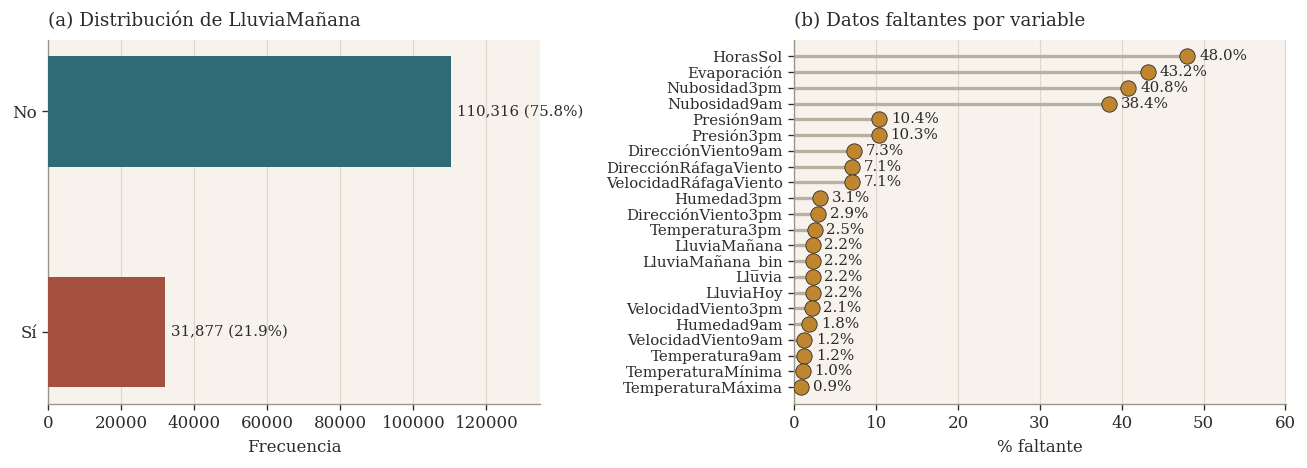

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# ------------------------------------------------------------
# (a) Distribución de la variable objetivo
# ------------------------------------------------------------

vc = df["LluviaMañana"].value_counts()

# Mantener orden No / Sí
vc = vc.reindex(["No", "Sí"]).dropna()

ax[0].barh(
    vc.index,
    vc.values,
    color=[TEAL, BRICK],
    height=0.5,
    zorder=3
)

for i, v in enumerate(vc.values):
    ax[0].text(
        v + vc.max() * 0.015,
        i,
        f"{v:,} ({v/n*100:.1f}%)",
        va="center",
        fontsize=9,
        color=INK
    )

ax[0].set_xlim(0, vc.max() * 1.22)
ax[0].invert_yaxis()

ax[0].set_xlabel("Frecuencia")
ax[0].set_title("(a) Distribución de LluviaMañana")

ax[0].set_axisbelow(True)
ax[0].grid(
    axis="x",
    color=GRIDC,
    linewidth=0.7
)
ax[0].grid(axis="y", visible=False)


# ------------------------------------------------------------
# (b) Datos faltantes por variable
# ------------------------------------------------------------

miss = (df.isna().mean() * 100).sort_values(
    ascending=False
)

miss = miss[miss > 0]

yy = range(len(miss))

ax[1].hlines(
    list(yy),
    0,
    miss.values,
    color=STEM,
    lw=2.0,
    zorder=2
)

ax[1].scatter(
    miss.values,
    list(yy),
    color=OCHRE,
    s=85,
    zorder=3,
    edgecolor=INK,
    linewidth=0.5
)

for i, v in enumerate(miss.values):
    ax[1].text(
        v + miss.values.max() * 0.03,
        i,
        f"{v:.1f}%",
        va="center",
        fontsize=9,
        color=INK
    )

ax[1].set_yticks(list(yy))
ax[1].set_yticklabels(
    miss.index,
    fontsize=9
)

ax[1].invert_yaxis()

ax[1].set_xlim(
    0,
    miss.values.max() * 1.25
)

ax[1].set_xlabel("% faltante")
ax[1].set_title("(b) Datos faltantes por variable")

ax[1].set_axisbelow(True)

ax[1].grid(
    axis="x",
    color=GRIDC,
    linewidth=0.7
)

ax[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

#### Interpretación de la Figura 1

La Figura 1 permite observar dos características importantes del conjunto de datos.

En el gráfico (a) se observa una mayor frecuencia de la categoría `No` en la variable `LluviaMañana`, lo que confirma que existen más días sin lluvia al día siguiente que días con precipitación.

Esta diferencia evidencia un desbalance de la variable objetivo.

En el gráfico (b) se observa que la cantidad de datos faltantes varía entre las diferentes variables meteorológicas, existiendo algunas columnas con una proporción considerablemente mayor de información ausente.

Estas diferencias deben considerarse al seleccionar las variables utilizadas en los análisis posteriores.

### 2.3 Figura 2. Distribución de variables numéricas

Se analiza la distribución de tres variables meteorológicas relevantes del conjunto de datos:

- `TemperaturaMáxima`
- `Humedad3pm`
- `Lluvia`

Los histogramas permiten observar la concentración de los datos, la forma de las distribuciones, posibles asimetrías y la presencia de valores extremos.

Para las variables de temperatura y humedad se utiliza la media como referencia. En el caso de la lluvia se utiliza la mediana, debido a que esta variable puede presentar una distribución fuertemente asimétrica.

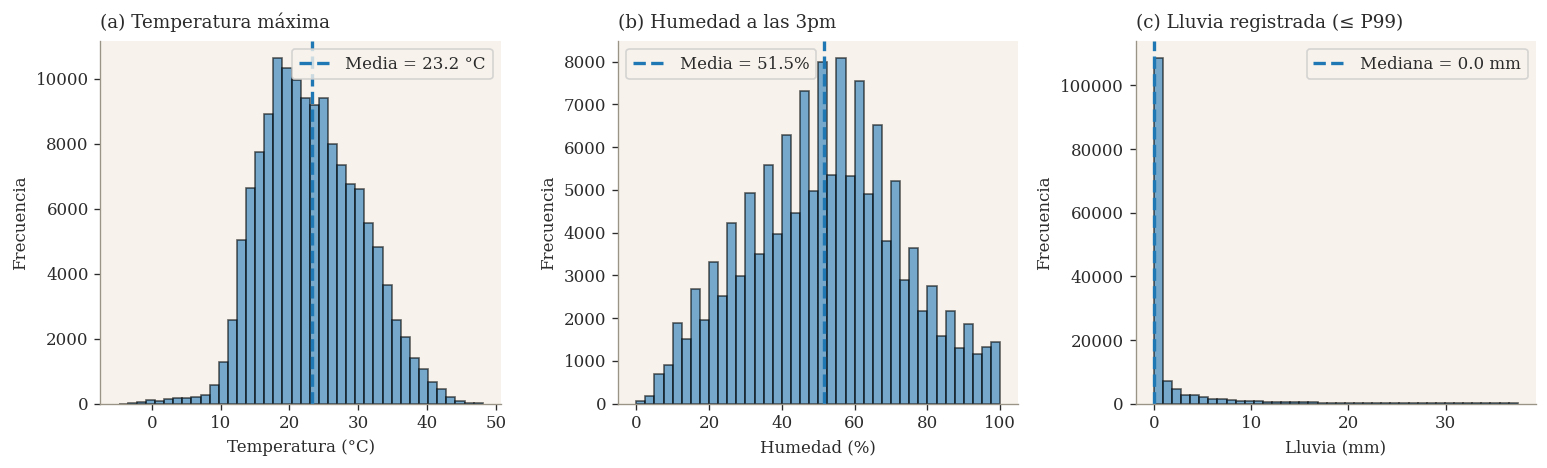

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

# ------------------------------------------------------------
# (a) Temperatura máxima
# ------------------------------------------------------------

temp = df["TemperaturaMáxima"].dropna()

ax[0].hist(
    temp,
    bins=40,
    alpha=0.6,
    edgecolor="black"
)

media_temp = temp.mean()

ax[0].axvline(
    media_temp,
    linestyle="--",
    linewidth=2,
    label=f"Media = {media_temp:.1f} °C"
)

ax[0].set_title("(a) Temperatura máxima")
ax[0].set_xlabel("Temperatura (°C)")
ax[0].set_ylabel("Frecuencia")
ax[0].legend()


# ------------------------------------------------------------
# (b) Humedad a las 3pm
# ------------------------------------------------------------

humedad = df["Humedad3pm"].dropna()

ax[1].hist(
    humedad,
    bins=40,
    alpha=0.6,
    edgecolor="black"
)

media_humedad = humedad.mean()

ax[1].axvline(
    media_humedad,
    linestyle="--",
    linewidth=2,
    label=f"Media = {media_humedad:.1f}%"
)

ax[1].set_title("(b) Humedad a las 3pm")
ax[1].set_xlabel("Humedad (%)")
ax[1].set_ylabel("Frecuencia")
ax[1].legend()


# ------------------------------------------------------------
# (c) Lluvia
# ------------------------------------------------------------

lluvia = df["Lluvia"].dropna()

# Percentil 99 para facilitar la visualización
p99 = lluvia.quantile(0.99)

ax[2].hist(
    lluvia[lluvia <= p99],
    bins=40,
    alpha=0.6,
    edgecolor="black"
)

mediana_lluvia = lluvia.median()

ax[2].axvline(
    mediana_lluvia,
    linestyle="--",
    linewidth=2,
    label=f"Mediana = {mediana_lluvia:.1f} mm"
)

ax[2].set_title("(c) Lluvia registrada (≤ P99)")
ax[2].set_xlabel("Lluvia (mm)")
ax[2].set_ylabel("Frecuencia")
ax[2].legend()

plt.tight_layout()
plt.show()

#### Interpretación de la Figura 2

La Figura 2 permite observar diferencias importantes en la distribución de las variables meteorológicas analizadas.

La `TemperaturaMáxima` presenta una distribución continua en la que la mayor parte de las observaciones se concentra alrededor de valores centrales. La línea discontinua representa la temperatura máxima promedio registrada en el conjunto de datos.

La variable `Humedad3pm` también presenta una distribución continua, aunque su forma puede mostrar una mayor dispersión dependiendo de las condiciones meteorológicas registradas.

En cambio, la variable `Lluvia` presenta una distribución fuertemente asimétrica hacia la derecha. La mayoría de las observaciones corresponde a valores bajos o cercanos a cero, mientras que una menor cantidad de registros presenta precipitaciones considerablemente más altas.

Debido a esta asimetría, la mediana constituye una medida de tendencia central más representativa para la cantidad de lluvia que la media.

Para facilitar la visualización de esta variable se muestran los valores hasta el percentil 99. Este ajuste se realiza únicamente en el gráfico y no implica la eliminación de observaciones del conjunto de datos.

### 2.4 Figura 3. Matriz de correlaciones

Se calcula la correlación de Pearson entre las variables numéricas del conjunto de datos meteorológico.

La matriz de correlaciones permite identificar relaciones lineales positivas o negativas entre las variables.

- Valores cercanos a **1** indican una relación positiva fuerte.
- Valores cercanos a **-1** indican una relación negativa fuerte.
- Valores cercanos a **0** indican una relación lineal débil.

La variable objetivo `LluviaMañana_bin` se excluye de esta matriz para analizar solamente las relaciones existentes entre las variables meteorológicas.

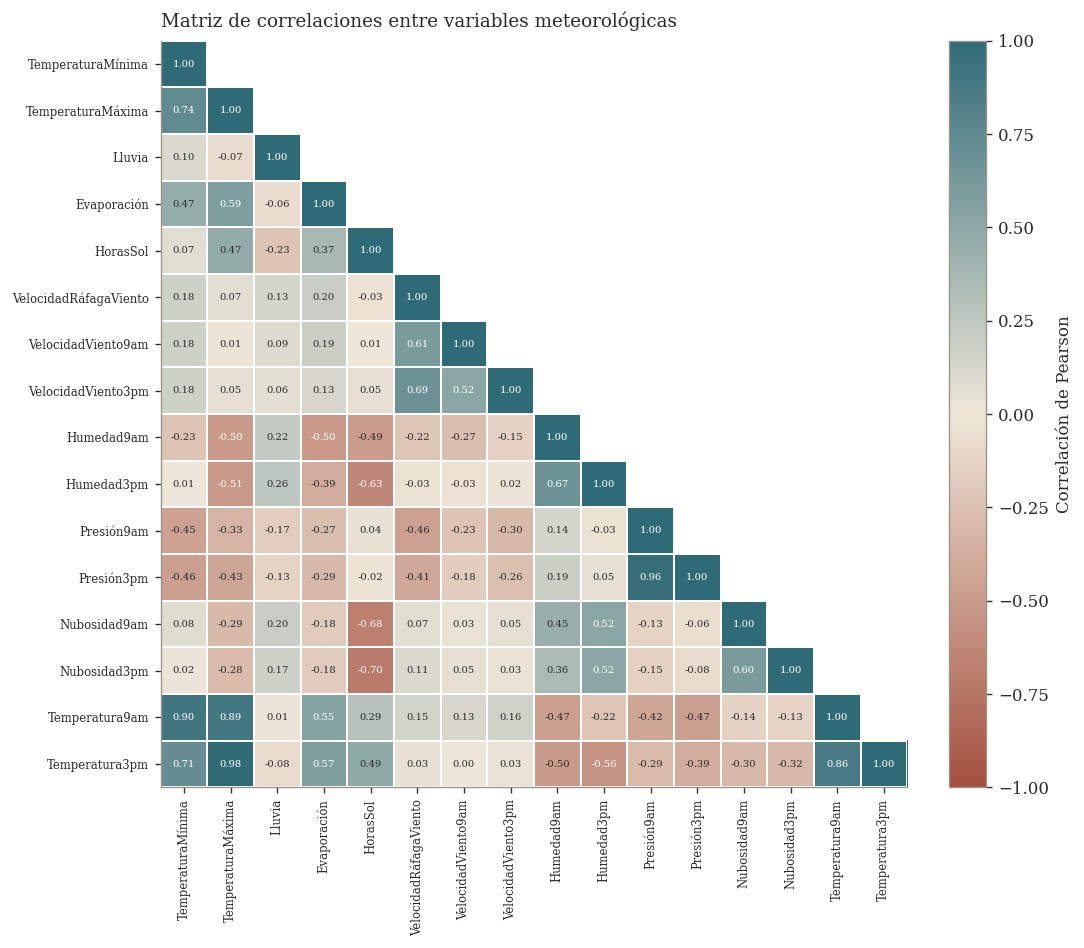

In [18]:
# Seleccionar variables numéricas y excluir la variable objetivo binaria
corr = df.select_dtypes(include=np.number).drop(
    columns=["LluviaMañana_bin"],
    errors="ignore"
).corr()

# Acortar etiquetas solo para visualización
labels = [c[:22] for c in corr.columns]

# Mostrar solamente el triángulo inferior de la matriz
M = np.ma.masked_array(
    corr.values,
    mask=np.triu(
        np.ones_like(corr.values, dtype=bool),
        k=1
    )
)

fig, ax = plt.subplots(figsize=(10, 8))

ax.set_facecolor("white")

im = ax.imshow(
    M,
    cmap=cmap_corr,
    vmin=-1,
    vmax=1
)

# Etiquetas de los ejes
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(
    labels,
    rotation=90,
    fontsize=7
)

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(
    labels,
    fontsize=7
)

# Mostrar el valor de cada correlación
for i in range(len(corr)):
    for j in range(len(corr)):
        if j <= i:
            v = corr.values[i, j]

            ax.text(
                j,
                i,
                f"{v:.2f}",
                ha="center",
                va="center",
                fontsize=6,
                color="white" if abs(v) > 0.5 else INK
            )

# Líneas de separación
ax.set_xticks(
    np.arange(-0.5, len(labels), 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(labels), 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=1.2
)

ax.tick_params(
    which="minor",
    length=0
)

# Barra de colores
cb = fig.colorbar(
    im,
    fraction=0.046,
    pad=0.04
)

cb.set_label(
    "Correlación de Pearson"
)

ax.set_title(
    "Matriz de correlaciones entre variables meteorológicas"
)

plt.tight_layout()
plt.show()

#### Interpretación de la Figura 3

La matriz de correlaciones muestra relaciones fuertes entre variables meteorológicas que representan fenómenos similares.

La relación más alta se observa entre `TemperaturaMáxima` y `Temperatura3pm` (**r = 0,98**), seguida por `Presión9am` y `Presión3pm` (**r = 0,96**).

También se observa una relación positiva elevada entre `TemperaturaMínima` y `Temperatura9am` (**r = 0,90**).

Entre las relaciones negativas destacan `HorasSol` y `Nubosidad3pm` (**r = -0,70**), así como `Humedad3pm` y `HorasSol` (**r = -0,63**).

Estos resultados son coherentes con el comportamiento meteorológico esperado y muestran que existen variables que aportan información similar.

### 2.5 Análisis bivariado con variables derivadas

El conjunto de datos contiene principalmente variables meteorológicas numéricas y categóricas.

Para facilitar el análisis bivariado se construyen nuevas variables categóricas a partir de algunas variables numéricas relevantes:

- Tramos de humedad a las 3pm.
- Tramos de temperatura máxima.
- Condición de lluvia durante el día actual.

Estas variables permiten analizar cómo cambia la proporción de días con lluvia al día siguiente según distintas condiciones meteorológicas.

In [19]:
# ============================================================
# Variables categóricas derivadas
# ============================================================

# 1. Tramos de humedad a las 3pm
df["TramoHumedad3pm"] = pd.cut(
    df["Humedad3pm"],
    bins=[0, 30, 50, 70, 101],
    labels=[
        "Baja (<30%)",
        "Media (30-49%)",
        "Alta (50-69%)",
        "Muy alta (≥70%)"
    ],
    include_lowest=True,
    right=False
)

# 2. Tramos de temperatura máxima
df["TramoTemperaturaMáxima"] = pd.cut(
    df["TemperaturaMáxima"],
    bins=[-20, 15, 20, 25, 30, 60],
    labels=[
        "<15 °C",
        "15-19 °C",
        "20-24 °C",
        "25-29 °C",
        "≥30 °C"
    ],
    right=False
)

# 3. Verificar las nuevas variables
df[
    [
        "Humedad3pm",
        "TramoHumedad3pm",
        "TemperaturaMáxima",
        "TramoTemperaturaMáxima",
        "LluviaHoy",
        "LluviaMañana",
        "LluviaMañana_bin"
    ]
].head(10)

,Humedad3pm,TramoHumedad3pm,TemperaturaMáxima,TramoTemperaturaMáxima,LluviaHoy,LluviaMañana,LluviaMañana_bin
0,22.0,Baja (<30%),22.9,20-24 °C,No,No,0.0
1,25.0,Baja (<30%),25.1,25-29 °C,No,No,0.0
2,30.0,Media (30-49%),25.7,25-29 °C,No,No,0.0
3,16.0,Baja (<30%),28.0,25-29 °C,No,No,0.0
4,33.0,Media (30-49%),32.3,≥30 °C,No,No,0.0
5,23.0,Baja (<30%),29.7,25-29 °C,No,No,0.0
6,19.0,Baja (<30%),25.0,25-29 °C,No,No,0.0
7,19.0,Baja (<30%),26.7,25-29 °C,No,No,0.0
8,9.0,Baja (<30%),31.9,≥30 °C,No,Sí,1.0
9,27.0,Baja (<30%),30.1,≥30 °C,Sí,No,0.0


#### Interpretación de las variables derivadas

Las nuevas variables permiten agrupar observaciones meteorológicas en categorías más fáciles de interpretar.

Los tramos de humedad permiten comparar la frecuencia de lluvia al día siguiente entre condiciones de baja, media, alta y muy alta humedad.

De forma similar, los tramos de temperatura máxima permiten evaluar si la proporción de lluvia al día siguiente cambia según diferentes condiciones térmicas.

La variable `LluviaHoy` se mantiene como variable categórica original y permitirá analizar si la presencia de lluvia durante el día actual se relaciona con una mayor probabilidad de lluvia al día siguiente.

Estas categorías serán utilizadas en las siguientes visualizaciones para comparar la proporción de `LluviaMañana`.

In [20]:
# Proporción global de lluvia al día siguiente
gm = df["LluviaMañana_bin"].mean() * 100

print(
    f"Porcentaje global de días con lluvia al día siguiente: "
    f"{gm:.2f}%"
)

Porcentaje global de días con lluvia al día siguiente: 22.42%


#### Interpretación de la proporción global

La media de la variable binaria `LluviaMañana_bin` representa directamente la proporción de observaciones en las que se registró lluvia al día siguiente.

Este porcentaje constituye una referencia global para comparar posteriormente los distintos grupos de humedad, temperatura y condición de lluvia actual.

Un grupo con un porcentaje superior a esta referencia presentará una frecuencia de lluvia al día siguiente mayor que el promedio general del conjunto de datos.

### 2.6 Figura 4. Lluvia al día siguiente según humedad y temperatura máxima

Se analiza cómo cambia la proporción de días con lluvia al día siguiente según dos variables categóricas derivadas:

- Tramos de humedad a las 3pm.
- Tramos de temperatura máxima.

En ambos gráficos se incluye como referencia el porcentaje global de días con lluvia al día siguiente.

Esto permite identificar qué grupos presentan una frecuencia de lluvia superior o inferior al promedio general del conjunto de datos.

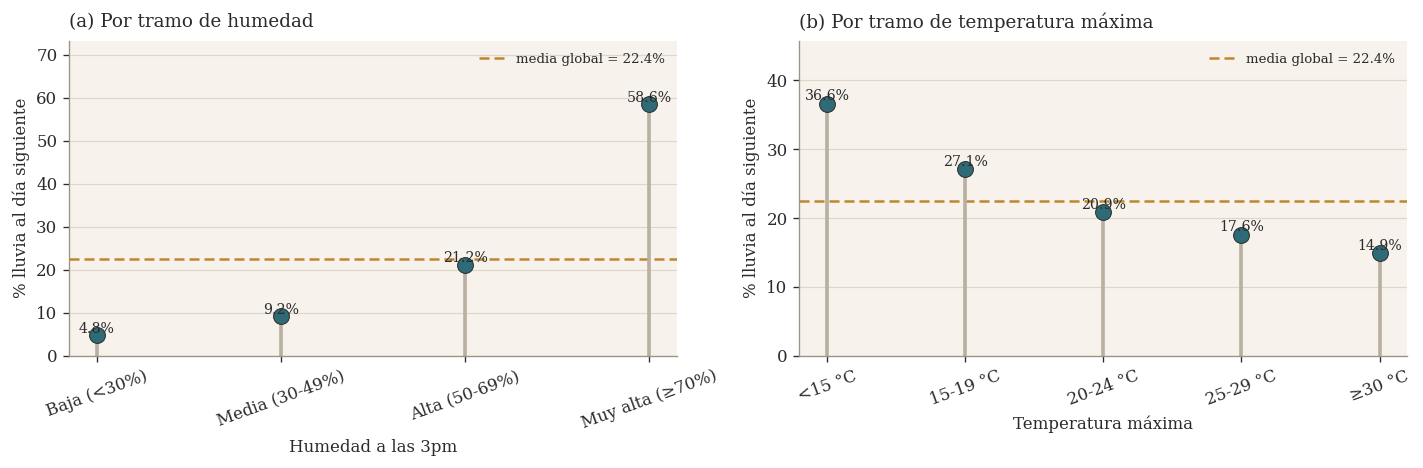

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

def lollipop_lluvia(a, variable, titulo, xlab):
    # Porcentaje de lluvia al día siguiente por categoría
    t = (
        df.groupby(variable, observed=True)["LluviaMañana_bin"]
        .mean() * 100
    )

    xx = range(len(t))

    # Línea con porcentaje global
    a.axhline(
        gm,
        color=OCHRE,
        ls=(0, (4, 2)),
        lw=1.5,
        zorder=2,
        label=f"media global = {gm:.1f}%"
    )

    # Líneas verticales
    a.vlines(
        list(xx),
        0,
        t.values,
        color=STEM,
        lw=2.2,
        zorder=2
    )

    # Puntos
    a.scatter(
        list(xx),
        t.values,
        color=TEAL,
        s=90,
        zorder=3,
        edgecolor=INK,
        linewidth=0.6
    )

    # Etiquetas de porcentaje
    for xi, yi in zip(xx, t.values):
        a.text(
            xi,
            yi + 0.5,
            f"{yi:.1f}%",
            ha="center",
            fontsize=8.5,
            color=INK
        )

    a.set_xticks(list(xx))
    a.set_xticklabels(
        t.index.astype(str),
        rotation=20
    )

    a.set_title(titulo)
    a.set_xlabel(xlab)
    a.set_ylabel("% lluvia al día siguiente")

    a.set_ylim(
        0,
        t.values.max() * 1.25
    )

    grid_h(a)

    a.legend(
        fontsize=8,
        frameon=False
    )


# ------------------------------------------------------------
# Gráfico (a): Humedad
# ------------------------------------------------------------

lollipop_lluvia(
    ax[0],
    "TramoHumedad3pm",
    "(a) Por tramo de humedad",
    "Humedad a las 3pm"
)

# ------------------------------------------------------------
# Gráfico (b): Temperatura máxima
# ------------------------------------------------------------

lollipop_lluvia(
    ax[1],
    "TramoTemperaturaMáxima",
    "(b) Por tramo de temperatura máxima",
    "Temperatura máxima"
)

plt.tight_layout()
plt.savefig(
    "fig_bivariado_clima.png",
    bbox_inches="tight"
)
plt.show()

#### Interpretación de la Figura 4
La frecuencia de lluvia al día siguiente aumenta de manera marcada a medida que aumenta la humedad registrada a las 3pm.

En condiciones de humedad baja, solamente el **4,8 %** de las observaciones presenta lluvia al día siguiente. Esta proporción aumenta a **9,2 %** para humedad media y a **21,2 %** para humedad alta.

Cuando la humedad alcanza niveles muy altos (≥70 %), la proporción aumenta hasta **58,2 %**, valor considerablemente superior a la media global de **22,4 %**.

Por otra parte, el análisis por temperatura máxima muestra una tendencia inversa. Los días con temperaturas inferiores a 15 °C presentan un **36,6 %** de lluvia al día siguiente, mientras que para temperaturas iguales o superiores a 30 °C la proporción disminuye hasta aproximadamente **14,9 %**.

Estos resultados sugieren una asociación importante entre las condiciones de humedad y temperatura y la ocurrencia de lluvia al día siguiente.


## 3. Estimación de parámetros

Se realizan estimaciones puntuales e intervalos de confianza al 95 % para tres variables numéricas del conjunto de datos meteorológico:

- Temperatura máxima.
- Humedad a las 3pm.
- Presión a las 3pm.

Además, se estima la proporción de observaciones en las que se registra lluvia al día siguiente.

Para las medias y la proporción se utiliza un intervalo basado en la aproximación normal (método de Wald), siguiendo el procedimiento aplicado en el notebook original.

Debido al gran tamaño muestral, la aproximación normal resulta adecuada para estas estimaciones.

### 3.1 Intervalos de confianza para medias

In [22]:
# Nivel de confianza del 95 %
z = stats.norm.ppf(0.975)

# ------------------------------------------------------------
# Función para intervalo de confianza de una media
# ------------------------------------------------------------

def ic_media(x):
    x = pd.Series(x).dropna()

    media = x.mean()
    error_estandar = x.std(ddof=1) / np.sqrt(len(x))

    limite_inferior = media - z * error_estandar
    limite_superior = media + z * error_estandar

    return (
        media,
        limite_inferior,
        limite_superior,
        len(x)
    )


# ------------------------------------------------------------
# Función para intervalo de confianza de una proporción
# ------------------------------------------------------------

def ic_prop(k, n):
    p = k / n

    error_estandar = np.sqrt(
        p * (1 - p) / n
    )

    limite_inferior = p - z * error_estandar
    limite_superior = p + z * error_estandar

    return (
        p,
        limite_inferior,
        limite_superior
    )


# ------------------------------------------------------------
# Intervalos para variables numéricas
# ------------------------------------------------------------

variables_ic = [
    ("TemperaturaMáxima", "Temperatura máxima (°C)"),
    ("Humedad3pm", "Humedad 3pm (%)"),
    ("Presión3pm", "Presión 3pm")
]

for columna, nombre in variables_ic:

    media, li, ls, nn = ic_media(df[columna])

    print(
        f"{nombre:25s}: "
        f"estimación = {media:8.2f}   "
        f"IC95% [{li:.2f}, {ls:.2f}]   "
        f"(n = {nn:,})"
    )



Temperatura máxima (°C)  : estimación =    23.22   IC95% [23.18, 23.26]   (n = 144,199)
Humedad 3pm (%)          : estimación =    51.54   IC95% [51.43, 51.65]   (n = 140,953)
Presión 3pm              : estimación =  1015.26   IC95% [1015.22, 1015.29]   (n = 130,432)


### 3.2 Intervalo de confianza para la proporción de lluvia al día siguiente

In [23]:

# ------------------------------------------------------------
# Intervalo para proporción de lluvia al día siguiente
# ------------------------------------------------------------

objetivo = df["LluviaMañana_bin"].dropna()

k = objetivo.sum()
n_obj = len(objetivo)

p, li, ls = ic_prop(k, n_obj)

print(
    f'{"Proporción LluviaMañana":25s}: '
    f"estimación = {p:.4f}   "
    f"IC95% [{li:.4f}, {ls:.4f}]   "
    f"(n = {n_obj:,})"
)

Proporción LluviaMañana  : estimación = 0.2242   IC95% [0.2220, 0.2263]   (n = 142,193)


#### Interpretación de las estimaciones

Los intervalos de confianza obtenidos permiten estimar los valores medios de las principales variables meteorológicas y cuantificar la incertidumbre asociada a dichas estimaciones.

Debido al elevado número de observaciones disponibles, los intervalos obtenidos son relativamente estrechos, lo que indica una alta precisión en la estimación de las medias poblacionales.

La estimación de la proporción de `LluviaMañana` permite cuantificar el porcentaje de observaciones en las que se registra lluvia al día siguiente.

El intervalo de confianza del 95 % proporciona un rango plausible para esta proporción en la población representada por el conjunto de datos.

## 4. Pruebas de hipótesis

En esta etapa se realizan pruebas estadísticas para evaluar si las diferencias observadas entre distintos grupos pueden considerarse estadísticamente significativas.

Se aplicarán dos pruebas:

- Prueba t de Welch para comparar medias entre dos grupos independientes.
- Prueba chi-cuadrado para evaluar asociación entre variables categóricas.

Estas pruebas permiten complementar el análisis descriptivo con evidencia inferencial.

### 4.1 Prueba t de Welch: humedad según lluvia al día siguiente

Se evalúa si la humedad media registrada a las 3pm es diferente entre los días en que se registra lluvia al día siguiente y aquellos en que no se registra.

Se plantean las siguientes hipótesis:

- **H₀:** la humedad media a las 3pm es igual en ambos grupos.
- **H₁:** la humedad media a las 3pm es diferente entre ambos grupos.

Se utiliza una prueba t de Welch, ya que permite comparar las medias de dos grupos independientes sin asumir igualdad de varianzas.

In [24]:
# Separar los dos grupos
humedad_si = df.loc[
    df["LluviaMañana"] == "Sí",
    "Humedad3pm"
].dropna()

humedad_no = df.loc[
    df["LluviaMañana"] == "No",
    "Humedad3pm"
].dropna()

# Mostrar medias de ambos grupos
print(f"Humedad media cuando llueve mañana: {humedad_si.mean():.2f}%")
print(f"Humedad media cuando no llueve mañana: {humedad_no.mean():.2f}%")

# Prueba t de Welch
t_stat, p_valor = stats.ttest_ind(
    humedad_si,
    humedad_no,
    equal_var=False
)

print(f"\nEstadístico t = {t_stat:.4f}")
print(f"Valor p = {p_valor:.6f}")
print("Verificación de los grupos:\n")

print(
    f"Lluvia mañana = Sí: "
    f"n = {len(humedad_si):,}, "
    f"media = {humedad_si.mean():.2f}, "
    f"sd = {humedad_si.std(ddof=1):.2f}, "
    f"asimetría = {humedad_si.skew():.2f}"
)

print(
    f"Lluvia mañana = No: "
    f"n = {len(humedad_no):,}, "
    f"media = {humedad_no.mean():.2f}, "
    f"sd = {humedad_no.std(ddof=1):.2f}, "
    f"asimetría = {humedad_no.skew():.2f}"
)

# Tamaño del efecto: d de Cohen
n1 = len(humedad_si)
n0 = len(humedad_no)

sp = np.sqrt(
    ((n1 - 1) * humedad_si.var(ddof=1) +
     (n0 - 1) * humedad_no.var(ddof=1))
    / (n1 + n0 - 2)
)

d_cohen = (
    humedad_si.mean() - humedad_no.mean()
) / sp

print(f"\nd de Cohen = {d_cohen:.3f}")

Humedad media cuando llueve mañana: 68.80%
Humedad media cuando no llueve mañana: 46.51%

Estadístico t = 182.6077
Valor p = 0.000000
Verificación de los grupos:

Lluvia mañana = Sí: n = 30,913, media = 68.80, sd = 19.04, asimetría = -0.52
Lluvia mañana = No: n = 107,670, media = 46.51, sd = 18.49, asimetría = -0.04

d de Cohen = 1.198


#### Interpretación de la prueba t de Welch

La humedad media registrada a las 3pm fue de **68,80 %** en los días en que se registró lluvia al día siguiente y de **46,51 %** en los días en que no se registró lluvia.

La diferencia entre ambos grupos es de aproximadamente **22,29 puntos porcentuales**, lo que muestra una separación importante entre las condiciones de humedad asociadas a cada grupo.

La prueba t de Welch obtuvo un estadístico de **t = 182,61** y un **valor p < 0,001**. Dado que este valor es inferior al nivel de significancia de 0,05, se rechaza la hipótesis nula de igualdad de medias.

Por lo tanto, existe evidencia estadísticamente significativa de que la humedad media a las 3pm difiere entre los días en que llueve y no llueve al día siguiente.

En cuanto a la dispersión, ambos grupos presentan desviaciones estándar similares: **19,04** para los días con lluvia al día siguiente y **18,49** para los días sin lluvia al día siguiente. La asimetría es leve en ambos casos, con un valor de **-0,52** para el grupo con lluvia y **-0,04** para el grupo sin lluvia.

Además, el tamaño del efecto medido mediante **d de Cohen = 1,198** indica una diferencia de magnitud grande entre ambos grupos. Esto significa que la diferencia observada no solo es estadísticamente significativa, sino también relevante desde el punto de vista práctico.

En conjunto, los resultados muestran que una mayor humedad durante la tarde está fuertemente asociada con la ocurrencia de lluvia al día siguiente. Sin embargo, esta asociación estadística no implica causalidad.

### 4.2 Figura 5. Distribución de la humedad por grupo y lluvia al día siguiente según lluvia actual

Se presentan dos visualizaciones complementarias a las pruebas de hipótesis.

En el panel (a) se compara la distribución de la humedad registrada a las 3pm entre los días en que no llueve y sí llueve al día siguiente.

En el panel (b) se compara el porcentaje de días con lluvia al día siguiente según si durante el día actual hubo o no precipitación.

Estas visualizaciones permiten observar gráficamente las diferencias posteriormente evaluadas mediante la prueba t de Welch y la prueba chi-cuadrado.

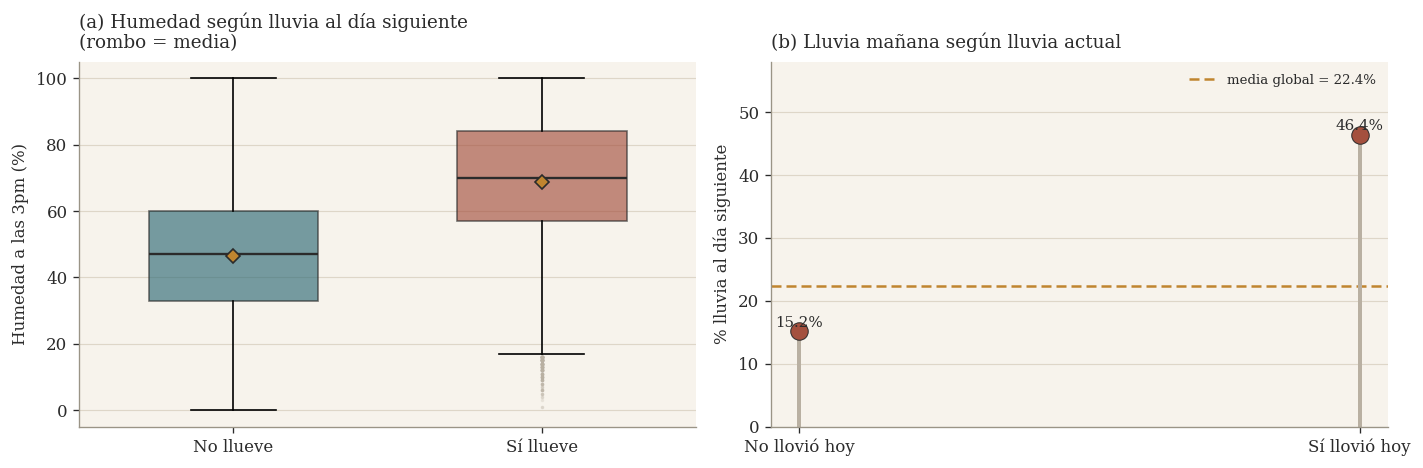

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# ============================================================
# (a) Boxplot de Humedad3pm según LluviaMañana
# ============================================================

humedad_no = df.loc[
    df["LluviaMañana"] == "No",
    "Humedad3pm"
].dropna()

humedad_si = df.loc[
    df["LluviaMañana"] == "Sí",
    "Humedad3pm"
].dropna()

bp = ax[0].boxplot(
    [humedad_no, humedad_si],
    tick_labels=["No llueve", "Sí llueve"],
    patch_artist=True,
    widths=0.55,
    showmeans=True,
    meanprops=dict(
        marker="D",
        markerfacecolor=OCHRE,
        markeredgecolor=INK,
        markersize=6
    ),
    medianprops=dict(
        color=INK,
        linewidth=1.4
    ),
    flierprops=dict(
        marker="o",
        markersize=2,
        markerfacecolor=STEM,
        markeredgecolor="none",
        alpha=0.25
    )
)

for patch, col in zip(
    bp["boxes"],
    [TEAL, BRICK]
):
    patch.set_facecolor(col)
    patch.set_alpha(0.65)
    patch.set_edgecolor(INK)

ax[0].set_ylabel("Humedad a las 3pm (%)")
ax[0].set_title(
    "(a) Humedad según lluvia al día siguiente\n"
    "(rombo = media)"
)

grid_h(ax[0])

# ============================================================
# (b) % de lluvia mañana según LluviaHoy
# ============================================================

tt = (
    df.dropna(
        subset=["LluviaHoy", "LluviaMañana_bin"]
    )
    .groupby(
        "LluviaHoy",
        observed=True
    )["LluviaMañana_bin"]
    .mean() * 100
)

tt = tt.reindex(["No", "Sí"]).dropna()

xx = range(len(tt))

ax[1].axhline(
    gm,
    color=OCHRE,
    ls=(0, (4, 2)),
    lw=1.5,
    zorder=2,
    label=f"media global = {gm:.1f}%"
)

ax[1].vlines(
    list(xx),
    0,
    tt.values,
    color=STEM,
    lw=2.4,
    zorder=2
)

ax[1].scatter(
    list(xx),
    tt.values,
    color=BRICK,
    s=110,
    zorder=3,
    edgecolor=INK,
    linewidth=0.6
)

for xi, yi in zip(xx, tt.values):
    ax[1].text(
        xi,
        yi + 0.7,
        f"{yi:.1f}%",
        ha="center",
        fontsize=9,
        color=INK
    )

ax[1].set_xticks(list(xx))
ax[1].set_xticklabels([
    "No llovió hoy",
    "Sí llovió hoy"
])

ax[1].set_ylabel("% lluvia al día siguiente")
ax[1].set_title(
    "(b) Lluvia mañana según lluvia actual"
)

ax[1].set_ylim(
    0,
    tt.values.max() * 1.25
)

grid_h(ax[1])

ax[1].legend(
    fontsize=8,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    "fig_hipotesis_clima.png",
    bbox_inches="tight"
)

plt.show()

#### Interpretación de la Figura 5

El panel (a) muestra una diferencia clara en la distribución de la humedad a las 3pm entre ambos grupos.

Los días asociados con lluvia al día siguiente presentan niveles de humedad considerablemente mayores. La humedad media fue de **68,80 %** cuando llovió al día siguiente y de **46,51 %** cuando no llovió.

Esta diferencia visual es coherente con el resultado de la prueba t de Welch, que mostró una diferencia estadísticamente significativa entre ambos grupos.

En el panel (b) se observa que la proporción de lluvia al día siguiente varía según la presencia de lluvia durante el día actual.

Esta diferencia visual es consistente con la prueba chi-cuadrado, que indicó una asociación estadísticamente significativa entre `LluviaHoy` y `LluviaMañana`.

Las visualizaciones complementan los resultados inferenciales y permiten apreciar gráficamente las diferencias existentes entre los grupos.

### 4.3 Prueba chi-cuadrado: asociación entre LluviaHoy y LluviaMañana

Se evalúa si existe asociación entre la presencia de lluvia durante el día actual (`LluviaHoy`) y la presencia de lluvia durante el día siguiente (`LluviaMañana`).

Se plantean las siguientes hipótesis:

- **H₀:** `LluviaHoy` y `LluviaMañana` son variables independientes.
- **H₁:** existe asociación entre `LluviaHoy` y `LluviaMañana`.

Para evaluar esta relación se utiliza una prueba chi-cuadrado de independencia.

In [26]:
# Tabla de contingencia
tabla_contingencia = pd.crosstab(
    df["LluviaHoy"],
    df["LluviaMañana"]
)

display(tabla_contingencia)

# Chi-cuadrado
chi2, p_valor_chi, gl, esperados = stats.chi2_contingency(
    tabla_contingencia
)

# V de Cramér
N = tabla_contingencia.values.sum()

V = np.sqrt(
    chi2 /
    (N * (min(tabla_contingencia.shape) - 1))
)

print(f"Frecuencia esperada mínima = {esperados.min():.2f}")
print(f"Chi-cuadrado = {chi2:.4f}")
print(f"Grados de libertad = {gl}")
print(f"Valor p = {p_valor_chi:.3e}")
print(f"V de Cramér = {V:.3f}")

# Riesgos
riesgo_si = (
    tabla_contingencia.loc["Sí", "Sí"]
    / tabla_contingencia.loc["Sí"].sum()
)

riesgo_no = (
    tabla_contingencia.loc["No", "Sí"]
    / tabla_contingencia.loc["No"].sum()
)

RR = riesgo_si / riesgo_no

print(
    f"\nLluvia mañana si llovió hoy: "
    f"{riesgo_si*100:.1f}%"
)

print(
    f"Lluvia mañana si no llovió hoy: "
    f"{riesgo_no*100:.1f}%"
)

print(
    f"Riesgo relativo = {RR:.2f}"
)

LluviaMañana,No,Sí
LluviaHoy,,
No,92728,16604
Sí,16858,14597


Frecuencia esperada mínima = 6971.01
Chi-cuadrado = 13799.4796
Grados de libertad = 1
Valor p = 0.000e+00
V de Cramér = 0.313

Lluvia mañana si llovió hoy: 46.4%
Lluvia mañana si no llovió hoy: 15.2%
Riesgo relativo = 3.06


#### Interpretación de la prueba chi-cuadrado

La prueba chi-cuadrado de independencia obtuvo un valor de **χ² = 13799,48**, con **1 grado de libertad** y un **valor p < 0,001**.

Dado que el valor p es inferior al nivel de significancia de 0,05, se rechaza la hipótesis nula de independencia entre `LluviaHoy` y `LluviaMañana`.

Por lo tanto, existe evidencia estadísticamente significativa de una asociación entre la presencia de lluvia durante el día actual y la ocurrencia de lluvia al día siguiente.

La frecuencia esperada mínima fue de **6971,01**, valor ampliamente superior a 5, por lo que se cumple adecuadamente uno de los principales supuestos de aplicación de la prueba chi-cuadrado.

El tamaño de la asociación, evaluado mediante **V de Cramér = 0,313**, indica una asociación de magnitud moderada entre ambas variables. Esto demuestra que la relación observada no solo es estadísticamente significativa debido al gran tamaño de la muestra, sino que también presenta una magnitud relevante.

Al analizar las proporciones, se observa que el **46,4 %** de los días en que llovió durante el día actual también registró lluvia al día siguiente. En cambio, cuando no llovió durante el día actual, solamente el **15,2 %** presentó lluvia al día siguiente.

El **riesgo relativo fue de 3,06**, lo que indica que, en este conjunto de datos, la proporción de lluvia al día siguiente es aproximadamente **3,06 veces mayor cuando ha llovido durante el día actual** que cuando no ha llovido.

En conjunto, los resultados muestran una asociación estadísticamente significativa y de magnitud moderada entre `LluviaHoy` y `LluviaMañana`. Sin embargo, esta relación corresponde a una asociación estadística y no implica que la lluvia de un día sea la causa directa de la lluvia del día siguiente.

## 5. Síntesis de resultados

El análisis realizado permitió estudiar la calidad, distribución y relaciones presentes en el conjunto de datos meteorológico `weatherAUS`.

La revisión inicial identificó la presencia de datos faltantes en distintas variables, por lo que se decidió evitar la eliminación global de registros y trabajar posteriormente con los casos disponibles para cada análisis. Los valores extremos tampoco fueron eliminados automáticamente, debido a que pueden representar fenómenos meteorológicos reales.

El análisis exploratorio permitió observar diferencias en las distribuciones de las variables meteorológicas. En particular, la cantidad de lluvia presenta una distribución fuertemente asimétrica, debido a la concentración de registros con precipitaciones bajas o nulas y a la existencia de una menor cantidad de eventos con precipitaciones elevadas.

La variable objetivo `LluviaMañana` presenta una mayor proporción de registros correspondientes a días sin lluvia que a días con lluvia, evidenciando un desbalance entre ambas categorías.

El análisis bivariado permitió estudiar cómo cambia la frecuencia de lluvia al día siguiente según distintas condiciones de humedad y temperatura.

La prueba t de Welch mostró que la humedad media a las 3pm fue de **68,80 %** cuando se registró lluvia al día siguiente y de **46,51 %** cuando no se registró lluvia. La diferencia fue de **22,29 puntos porcentuales**. El resultado de la prueba fue **t = 182,61** con **p < 0,001**, por lo que se rechazó la hipótesis nula de igualdad de medias. Esto evidencia una asociación estadísticamente significativa entre la humedad de la tarde y la ocurrencia de lluvia al día siguiente.

Por otra parte, la prueba chi-cuadrado de independencia obtuvo **χ² = 13799,48**, con **1 grado de libertad** y **p < 0,001**. Por lo tanto, se rechazó la hipótesis de independencia entre `LluviaHoy` y `LluviaMañana`, concluyéndose que existe una asociación estadísticamente significativa entre ambas variables.

En conjunto, los resultados indican que variables como la humedad a las 3pm y la presencia de lluvia durante el día actual contienen información relevante para caracterizar la ocurrencia de lluvia al día siguiente.

Estas asociaciones no implican causalidad, pero constituyen antecedentes estadísticos relevantes para posteriores análisis y para el eventual desarrollo de modelos predictivos.